## ДЗ №2. Матричные факторизации

#### В этой домашке вам предстоит реализовать некоторые базовые модели матричной факторизации

#### Дата выдачи: 17.02.25

#### Мягкий дедлайн: 02.03.25 23:59 MSK

#### Жесткий дедлайн: 09.03.25 23:59 MSK

В этом задании мы будем работать с классическим для рекоендательных систем датасетом [MovieLens 1M](https://grouplens.org/datasets/movielens/1m/). Датасет содержит рейтинги оценки для 4000 фильмов от 6000 пользователей. Более подробное описание можете найти на странице с датасетом и в README файле

In [1]:
!wget https://files.grouplens.org/datasets/movielens/ml-1m.zip --no-check-certificate
!unzip ml-1m.zip
!cat ml-1m/README

--2026-10-02 19:21:36--  https://files.grouplens.org/datasets/movielens/ml-1m.zip
Resolving files.grouplens.org (files.grouplens.org)... 128.101.96.204
Connecting to files.grouplens.org (files.grouplens.org)|128.101.96.204|:443... connected.
  Unable to locally verify the issuer's authority.
HTTP request sent, awaiting response... 200 OK
Length: 5917549 (5,6M) [application/zip]
Saving to: 'ml-1m.zip'

     0K .......... .......... .......... .......... ..........  0%  150K 38s
    50K .......... .......... .......... .......... ..........  1%  307K 28s
   100K .......... .......... .......... .......... ..........  2% 15,2M 19s
   150K .......... .......... .......... .......... ..........  3% 48,0M 14s
   200K .......... .......... .......... .......... ..........  4%  306K 15s
   250K .......... .......... .......... .......... ..........  5% 54,4M 12s
   300K .......... .......... .......... .......... ..........  6% 39,3M 10s
   350K .......... .......... .......... .......... ....

In [2]:
import pandas as pd
import numpy as np
from typing import Union

In [3]:
df = pd.read_csv("ml-1m/ratings.dat", sep='::', names=['user_id', 'item_id', 'rating', 'timestamp'], engine='python')
df['datetime'] = pd.to_datetime(df['timestamp'], unit='s')
df.drop('timestamp', axis=1, inplace=True)
df.head()

,user_id,item_id,rating,datetime
0,1,1193,5,2000-12-31 22:12:40
1,1,661,3,2000-12-31 22:35:09
2,1,914,3,2000-12-31 22:32:48
3,1,3408,4,2000-12-31 22:04:35
4,1,2355,5,2001-01-06 23:38:11


In [4]:
value_counts = df['item_id'].value_counts()
filtered_values = value_counts[value_counts > 20].index
df = df[df['item_id'].isin(filtered_values)].copy()

In [5]:
train_end = '2000-12-01'
df_train = df[df['datetime'] < train_end].copy()
df_test = df[df['datetime'] >= train_end].copy()
df_train.shape, df_test.shape

((787420, 4), (207432, 4))

In [6]:
train_users = df_train['user_id'].unique()
train_items = df_train['item_id'].unique()

df_test = df_test[df_test['user_id'].isin(train_users)]
df_test = df_test[df_test['item_id'].isin(train_items)]
df_test.shape

(106471, 4)

In [7]:
from sklearn.preprocessing import LabelEncoder

user_le = LabelEncoder()
item_le = LabelEncoder()

df_train['user_id'] = user_le.fit_transform(df_train['user_id'])
df_train['item_id'] = item_le.fit_transform(df_train['item_id'])

df_test['user_id'] = user_le.transform(df_test['user_id'])
df_test['item_id'] = item_le.transform(df_test['item_id'])

In [8]:
print(df_train['user_id'].nunique(), df_train['user_id'].max())
print(df_train['item_id'].nunique(), df_train['item_id'].max())

5365 5364
3010 3009


In [9]:
df_train

,user_id,item_id,rating,datetime
100409,0,2994,3,2000-11-30 23:49:23
100411,0,929,4,2000-11-30 23:52:33
100412,0,567,4,2000-11-30 23:51:54
100415,0,3005,1,2000-11-30 23:58:06
100416,0,3006,4,2000-11-30 23:57:50
...,...,...,...,...
1000204,5364,814,1,2000-04-26 02:35:41
1000205,5364,817,5,2000-04-25 23:21:27
1000206,5364,478,5,2000-04-25 23:19:06
1000207,5364,819,4,2000-04-26 02:20:48


##### Задание 1. Напишем функцию, которая превратит датафрейм в матрицу интеракций. В функции df_to_matrix реализуйте функцию, которая принимает датафрейм и возвращает np.array матрицу интеракций. В функции df_to_coo реализуйте функцию, которая принимает датафрейм и возвращает разреженную матрицу интеракций в coo_array формате

In [10]:
def df_to_matrix(df: pd.DataFrame) -> np.ndarray:
    n_users = df['user_id'].max() + 1
    n_items = df['item_id'].max() + 1
    
    result = np.zeros((n_users,n_items))
    
    x = np.array(df['user_id'])
    y = np.array(df['item_id'])
    vals = np.array(df['rating'])
    
    result[x,y] = vals
    
    return result #shape ~ [n_users, n_items]

In [11]:
interactions = df_to_matrix(df_train)

In [13]:
df_train

,user_id,item_id,rating,datetime
100409,0,2994,3,2000-11-30 23:49:23
100411,0,929,4,2000-11-30 23:52:33
100412,0,567,4,2000-11-30 23:51:54
100415,0,3005,1,2000-11-30 23:58:06
100416,0,3006,4,2000-11-30 23:57:50
...,...,...,...,...
1000204,5364,814,1,2000-04-26 02:35:41
1000205,5364,817,5,2000-04-25 23:21:27
1000206,5364,478,5,2000-04-25 23:19:06
1000207,5364,819,4,2000-04-26 02:20:48


In [14]:
from scipy.sparse import coo_array

def df_to_coo(df: pd.DataFrame) -> coo_array:
    
    userId = np.array(df['user_id'])
    movieId = np.array(df['item_id'])
    rating = np.array(df['rating'])
    
    result = coo_array((rating, (userId, movieId)),
                       shape=(df['user_id'].nunique(),df['item_id'].nunique())).tocsr()

    return result # coo_array

In [15]:
coo_interactions = df_to_coo(df_train)

In [16]:
assert (interactions != 0).sum() == df_train.shape[0]
assert interactions[0, 2994] == 3
assert interactions[2369, 1203] == 5
assert interactions[1557, 459] == 3
assert np.allclose(coo_interactions.toarray(), interactions)

##### Задание 2.1. Рассмотрим [SVD](https://en.wikipedia.org/wiki/Singular_value_decomposition). Возьмите готовую реализуцию алгоритма из numpy.linalg или из scipy.linalg и примените алгоритм к матрицам интеракций, полученным в первом задании. Для работы со sparse матрицей обычная реализация svd не подойдет и нужно будет воспользоваться scipy.sparse.linalg.svds. Вам нужно разложить матрицу интеракций на 3 матрицы U, S, V, а затем перемножить их и восстановить изначальную матрицу. При полном разложении исходная матрица должна восстанавливаться максимально хорошо

In [17]:
from scipy.sparse.linalg import svds

In [18]:
def make_svd(interractions: Union[np.ndarray, coo_array], n_singular_values: int = -1):
    # функция должна работать и для полной матрицы и для sparse матрицы(вам поможет isinstance).
    # если n_singular_values = -1, то берем все сингулярные числа для полной матрицы
    # и все кроме одного сингулярного числа для coo-матрицы(иначе scipy.sparse.linalg.svds не будет работать)
    
    if isinstance(interractions, np.ndarray):
        U,S,Vt = np.linalg.svd(interactions)
        if n_singular_values!=-1:
            U = U[:, :n_singular_values]
            S = S[:n_singular_values]
            Vt = Vt[:n_singular_values, :]
    else:
        k = 0
        if n_singular_values!=-1:
            k = n_singular_values 
        else:
            k = min(df['user_id'].nunique(), df['item_id'].nunique())-1
            
        U,S,Vt = svds(interactions, k = k)

    new_S = np.zeros((U.shape[1], Vt.shape[0]))
    new_S[:len(S), :len(S)] = np.diag(S)
    
    return U, new_S, Vt

In [19]:
U, S, V = make_svd(interactions)
assert np.allclose(U @ S @ V, interactions)

In [20]:
U1, S1, V1 = make_svd(interactions, 10)
U, S, V = make_svd(coo_interactions, 10)
assert np.allclose(U1 @ S1 @ V1, U @ S @ V)

##### Задание 2.2. Теперь попробуем сделать рекомендации с помощью SVD. Мы научились восстанавливать исходную матрицу с помощью разложения, теперь же мы хотим порекомендовать пользователю айтемы, которые будут для него максимально релевантны(в восстановленной матрице у них будет самый высокий скор). Для каждого пользователя нужно будет найти индексы айтемов, которые имеют максимальный скор. При этом стоит обратить внимание, что мы не хотим рекомендовать пользователю айтемы, с которыми он уже взаимодействовал

In [21]:
def make_svd_recommendations(interractions: Union[np.ndarray, coo_array], n_singular_values: int = -1, top_k: int = 100):
    # Возвращает матрицу вида n_users, top_k, то есть для каждого пользователя возвращаем индексы 
    # top_k самых релевантный айтемов среди тех с которыми он еще не взаимодействовал

    U, S, V = make_svd(interractions, n_singular_values)
    
    scores = U @ S @ V
    
    if isinstance(interractions, coo_array):
        interractions = interractions.to_array()
    
    scores[interactions!=0] = -(10**9)

    recommendations = np.argsort(-scores, axis = 1)[:,:top_k]

    return recommendations #shape ~ [n_users, top_k]

In [22]:
U, S, V = make_svd(interactions, 10)
    
scores = U @ S @ V

# interractions = interactions.to_array()

scores[interactions!=0] = -(10**9)

recommendations = np.argsort(-scores, axis = 1)[:]

In [23]:
recs = make_svd_recommendations(interactions, -1, 100)
assert recs.shape == (interactions.shape[0], 100)

##### Задание 2.3. Теперь давайте посмотрим как будет зависеть качетво рекомендаций, от количества сингулярных чисел, которые мы возьмем в SVD разложении. Переберите n_singular_values из списка [1, 10, 50, 200, 1000] и посмотрите как будет изменяться метрика NDCG на тестовом датасете для таких рекомендаций и как будет меняться время вычисления. Для каждого графики зависимости метрики NDCG от n_singular_values и времени работы алгоритма от n_singular_values(Время работы будет меняться только для sparse-матрицы, стоит запускать алгоритм именно для нее)

In [24]:
from sklearn.metrics import ndcg_score
import time
import matplotlib.pyplot as plt

### NDCG@k
Normalized discounted cumulative gain

$DCG = \frac{1}{|r|} \sum_u{\frac{[bought fact]}{discount(i)}}$  

$discount(i) = 1$ if $i <= 2$,   
$discount(i) = log_2(i)$ if $i > 2$


(!) Считаем для первых k рекоммендаций   
(!) - существуют вариации с другими $discount(i)$  
i - ранк рекомендованного товара  
|r| - кол-во рекомендованных товаров 

$$NDCG = \frac{DCG}{ideal DCG}$$


In [25]:
def compute_gain(y_value: float, gain_scheme: str) -> float:
    if gain_scheme == "exp2":
        gain = 2 ** y_value - 1
    elif gain_scheme == "const":
        gain = y_value
    else:
        raise ValueError(f"{gain_scheme} method not supported, only exp2 and const.")
    return float(gain)

In [26]:
recommendations

array([[ 670,  638, 1203, ...,  825, 3006,   29],
       [ 638,  900,  929, ..., 1386,  462,  449],
       [ 875,  889,  449, ..., 1426, 1432,  497],
       ...,
       [ 876,  947, 1793, ..., 2041, 2568,  298],
       [ 672,  670,  725, ...,  915,  942,  981],
       [ 900, 1528,  947, ...,  641,   16,   24]], shape=(5365, 3010))

In [27]:
df_train['user_id'].nunique()

5365

In [28]:
df_test['user_id'].nunique()

1147

In [29]:
def ndcg(test: pd.DataFrame, recommendations: np.ndarray, top_k: int) -> float:
    
    discounts = 1 / np.log2(np.arange(2, top_k + 2))

    test_data = test.groupby('user_id').apply(lambda x : dict(zip(x['item_id'], x['rating'])), include_groups=False)
    ndcgs = []
    for i, recs in zip(test_data.index, test_data): #[1:]
        if i >= recommendations.shape[0]:
            continue
        k_recs = recommendations[i, :top_k]
        k_ratings = np.array([])
        for rec in k_recs:
            k_ratings = np.append(k_ratings, recs.get(rec, 0))
        dcg = (k_ratings * discounts).mean()

        ideal_ratings = np.array(sorted(recs.values(), reverse=True)[:top_k])
        ideal_dcg = (ideal_ratings * discounts[:len(ideal_ratings)]).mean()
        if ideal_dcg == 0:
            continue
        ndcg = dcg / ideal_dcg
        ndcgs += [ndcg]
    if len(ndcgs) == 0:
        return 0
    return np.mean(ndcgs)

In [30]:
ndcg(df_test, recommendations, 5)

np.float64(0.2743672150869128)

In [31]:
def plot_graphs(interractions: Union[np.ndarray, coo_array], top_k: int = 100):
    ndcgs = []
    times = []
    for n_singular_values in [1, 10, 50, 200, 1000]:
        start = time.time()
        recommendations = make_svd_recommendations(interractions, n_singular_values, top_k)
        times.append(time.time() - start)
        ndcgs.append(ndcg(df_test, recommendations, top_k=top_k))
    
    fig, axs = plt.subplots(2, 1)
    
    axs[0].plot([1, 10, 50, 200, 1000], ndcgs)
    axs[0].set_xscale('log')
    axs[1].plot([1, 10, 50, 200, 1000], times)
    axs[1].set_xscale('log')
    return ndcgs, times 
    

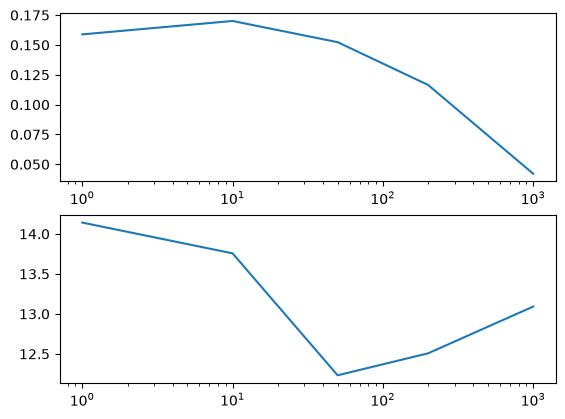

In [32]:
ndcgs, times = plot_graphs(interactions)

##### Задание 3.1. Перейдем к [ALS](http://yifanhu.net/PUB/cf.pdf). Возьмем реализацию iALS из библиотеки [implicit](https://benfred.github.io/implicit/api/models/cpu/als.html). Обучите ALS на нашем датасете, сделайте top_k рекомендации для юзеров из тестового датасета, и сравните метрики ALS с метриками, которые получились в SVD. Попробуйте перебрать гиперпараметры и найдите оптимальное число факторов, коэффициент alpha и коэффициент регуляризации.

In [33]:
!pip install implicit

In [34]:
import implicit
from scipy.sparse import csr_matrix

e:\Предметы\Магистратура\Семестр 3\Рекомендательные системы\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [35]:
def make_als_recommendations(
    interactions: Union[np.ndarray, coo_array], 
    top_k: int = 100, 
    n_factors: int = 100,
    alpha: float = 1.0,
    regularization: float = 0.01,
):
    interactions = csr_matrix(interactions)
    
    model = implicit.als.AlternatingLeastSquares(
        factors=n_factors,
        regularization=regularization,
        alpha=alpha,
        random_state=42
    )
    model.fit(interactions, show_progress=False)
    userids = np.arange(interactions.shape[0])
    recommendations = model.recommend(userids, interactions[userids], N=top_k, filter_already_liked_items=True)[0]
    return model, recommendations #shape ~ [n_users, top_k]

In [36]:
model, recs = make_als_recommendations(interactions)
assert recs.shape == (interactions.shape[0], 100)

e:\Предметы\Магистратура\Семестр 3\Рекомендательные системы\.venv\Lib\site-packages\implicit\cpu\als.py:96: RuntimeWarning: OpenBLAS is configured to use 16 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


In [37]:
metrics = pd.DataFrame()
for n_factors in [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 15, 25, 50, 100, 250, 500]:    
    _, recs = make_als_recommendations(interactions, n_factors=n_factors)
    metrics = pd.concat([metrics, pd.DataFrame({'n_factors': [n_factors], 'nDCG@k': [ndcg(df_test, recs, top_k=100)]})])
metrics

,n_factors,nDCG@k
0,1,0.159681
0,2,0.163232
0,3,0.162847
0,4,0.166853
0,5,0.169262
0,6,0.170479
0,7,0.169747
0,8,0.168999
0,9,0.167198
0,10,0.166723


In [38]:
metrics = pd.DataFrame()
for alpha in [0.1, 0.3, 0.5, 0.7, 1, 2, 5, 10, 15, 20]:
    _, recs = make_als_recommendations(interactions, n_factors=6, alpha=alpha)
    metrics = pd.concat([metrics, pd.DataFrame({'alpha': [alpha], 'nDCG@k': [ndcg(df_test, recs, top_k=100)]})])
metrics

,alpha,nDCG@k
0,0.1,0.170771
0,0.3,0.174855
0,0.5,0.172885
0,0.7,0.171416
0,1.0,0.170479
0,2.0,0.165766
0,5.0,0.159144
0,10.0,0.151917
0,15.0,0.146631
0,20.0,0.141609


In [39]:
metrics = pd.DataFrame()
for regularization in [0.01, 0.1, 0.5, 1]:
    _, recs = make_als_recommendations(interactions, n_factors=6, alpha=0.3, regularization=regularization)
    metrics = pd.concat([metrics, pd.DataFrame({'regularization': [regularization], 'nDCG@k': [ndcg(df_test, recs, top_k=100)]})])
metrics

,regularization,nDCG@k
0,0.01,0.174855
0,0.10,0.174713
0,0.50,0.174506
0,1.00,0.174732


In [40]:
model, recs = make_als_recommendations(interactions, n_factors=6, alpha=0.3, regularization=0.01)
ndcg(df_test, recs, top_k=100)

np.float64(0.17485481295063418)

##### Задание 3.2. Сделайте объяснение рекомендаций для нескольких юзеров(als.explain). Воспользуйтесь файлом movies.dat чтобы перейти от индексов фильмов к их названием

In [41]:
def item_id_to_movie_name(item_id):
    if item_id not in item_le.classes_:
        return 'UNKNOWN'
    return item_le.transform([item_id])[0]

movies = pd.read_csv("ml-1m/movies.dat", sep='::', names=['item_id', 'movie_name', 'movie_tags'], engine='python', encoding='latin-1')
movies.head()

,item_id,movie_name,movie_tags
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy


In [42]:
movies['item_id'] = movies['item_id'].apply(item_id_to_movie_name)
movies

,item_id,movie_name,movie_tags
0,0,Toy Story (1995),Animation|Children's|Comedy
1,1,Jumanji (1995),Adventure|Children's|Fantasy
2,2,Grumpier Old Men (1995),Comedy|Romance
3,3,Waiting to Exhale (1995),Comedy|Drama
4,4,Father of the Bride Part II (1995),Comedy
...,...,...,...
3878,3005,Meet the Parents (2000),Comedy
3879,3006,Requiem for a Dream (2000),Drama
3880,3007,Tigerland (2000),Drama
3881,3008,Two Family House (2000),Drama


In [43]:
user_id = 0
item_id = 1

explains = model.explain(user_id, csr_matrix(interactions[user_id]), item_id)[1]
explains

[(np.int32(2119), np.float64(0.0015186238285314541)),
 (np.int32(681), np.float64(0.0014353158186775552)),
 (np.int32(1982), np.float64(0.0012513097371168551)),
 (np.int32(1554), np.float64(0.0005886824207791001)),
 (np.int32(1541), np.float64(0.0005485756483877011)),
 (np.int32(682), np.float64(0.00039512735498575585)),
 (np.int32(2173), np.float64(0.00029900081559058303)),
 (np.int32(397), np.float64(0.0002193448451595014)),
 (np.int32(65), np.float64(0.00018501968818189905)),
 (np.int32(2467), np.float64(0.00018443492249169786))]

In [44]:
movies[movies['item_id'] == item_id]['movie_name'].item()

'Jumanji (1995)'

In [45]:
explains = [(movies[movies['item_id'] == x]['movie_name'].item(), y) for x, y in explains]
explains

[('Airplane! (1980)', np.float64(0.0015186238285314541)),
 ('Wizard of Oz, The (1939)', np.float64(0.0014353158186775552)),
 ('Star Wars: Episode I - The Phantom Menace (1999)',
  np.float64(0.0012513097371168551)),
 ('Return from Witch Mountain (1978)', np.float64(0.0005886824207791001)),
 ('Journey of Natty Gann, The (1985)', np.float64(0.0005485756483877011)),
 ('Gone with the Wind (1939)', np.float64(0.00039512735498575585)),
 ("Hard Day's Night, A (1964)", np.float64(0.00029900081559058303)),
 ('In the Army Now (1994)', np.float64(0.0002193448451595014)),
 ('Misérables, Les (1995)', np.float64(0.00018501968818189905)),
 ('Alive (1993)', np.float64(0.00018443492249169786))]

##### Задание 4. До этого мы работали с рейтингами, но как обсуждалось на лекции, implicit ALS отлично работает и с implicit фидбэком. Давайте попробуем преобразовать наш датасет(трейн и тест) следующим образом

1. Бинаризуем все рейтинги(заменим любую интеракцию пользователя на 1)
2. Заменим на 1 только рейтинги 4 и 5, а рейтинг ниже 4 заменим на 0
3. Заменим на 1 только рейтинги 4 и 5, а рейтинг ниже 4 заменим на -1
4. Заменим на 1 только рейтинги 4 и 5, а рейтинг ниже 4 заменим на -1 и добавим сглаживание по времени. То есть чем дальше была интеракция от максимальной даты трейна, тем с меньшим весом мы будем ее учитывать(например можно интеракции за последний месяц брать в исходном виде, и с каждым месяцем в прошлое умножать их на какой-нибудь коэффициент меньший 1). Таким образом более старые интеракции пользователя будут вносить меньший вклад в его интересы
5. Придумайте свой вариант(опционально)

Для каждой полученной матрицы обучите iALS и SVD и сравните их результаты между собой(преобразовывать нужно только обучающую выборку, тестовую оставляем неизменной)

In [46]:
df_train['rating']

100409     3
100411     4
100412     4
100415     1
100416     4
          ..
1000204    1
1000205    5
1000206    5
1000207    4
1000208    4
Name: rating, Length: 787420, dtype: int64

In [47]:
def test_1_binary(df):
    df_binary = df.copy()
    df_binary['rating'] = 1
    return df_binary

def test_2_binary(df):
    df_binary = df[df['rating'] >= 4].copy()
    df_binary['rating'] = 1
    return df_binary

def test_3_binary(df):
    df_binary = df.copy()
    df_binary['rating'] = df_binary['rating'].apply(lambda x : 1 if x >= 4 else -1)
    return df_binary

def test_4_time_weighted(df):
    df_time_weighted = df.copy()
    df_time_weighted['rating'] = df_time_weighted['rating'].apply(lambda x : 1 if x >= 4 else -1)
    df_max_dt = df_time_weighted['datetime'].max()
    coeff = (df_max_dt.year-df['datetime'].dt.year)*12+(df_max_dt.month-df['datetime'].dt.month)
    alpha = 0.99
    df_time_weighted['rating'] = df_time_weighted['rating']*(alpha**coeff)
    return df_time_weighted

In [48]:
transforms = [test_1_binary, test_2_binary, test_3_binary, test_4_time_weighted]
ndcgs = {'SVD': [], 'ALS':[]}

for transform in transforms:
    df_train_transfromed = transform(df_train)
    interactions = df_to_matrix(df_train_transfromed)
    
    svd_rec = make_svd_recommendations(interactions, 10)
    als_rec = make_als_recommendations(interactions, 100, 6, 0.3, 0.01)[1]
    
    ndcgs['SVD'].append(ndcg(df_test, svd_rec, 100))
    ndcgs['ALS'].append(ndcg(df_test, als_rec, 100))

In [49]:
import matplotlib.pyplot as plt

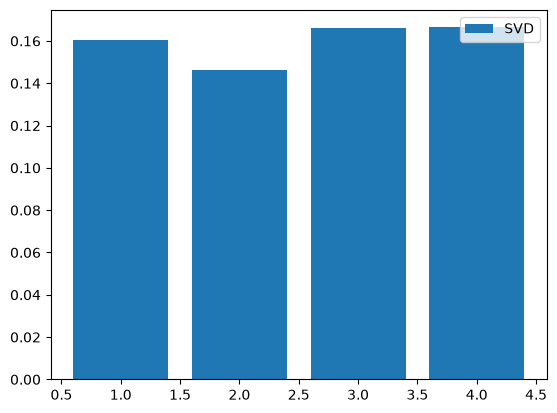

In [50]:
x = [1,2,3,4]
plt.bar(x, ndcgs['SVD'], label = 'SVD')
plt.legend()

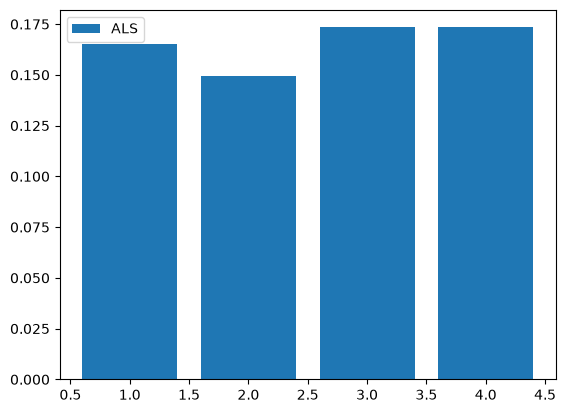

In [51]:
plt.bar(x, ndcgs['ALS'], label = 'ALS')
plt.legend()

##### Задание 5. iALS на numpy/torch. Давайте реализуем алгоритм iALS на нумпае или торче. Требуется реализовать алгорит, описанный в 4 части [статьи](http://yifanhu.net/PUB/cf.pdf). Обратите внимания на все оптимизации, которые они описывают в статье, чтобы сократить лишние вычисления. Hint: метрики у вашего алгоритма должны быть сравнимы с метриками ALS из библиотеки implicit

In [52]:
sparse_interractions = csr_matrix(df_to_matrix(df_train))

In [53]:
sparse_interractions[0].indices

array([  29,   65,   95,  236,  256,  397,  449,  510,  567,  635,  666,
        672,  674,  681,  682,  685,  687,  691,  718,  777,  808,  825,
        827,  846,  886,  891,  898,  908,  915,  929,  957,  985, 1152,
       1186, 1219, 1346, 1363, 1400, 1424, 1533, 1539, 1541, 1549, 1554,
       1639, 1709, 1815, 1982, 2028, 2070, 2112, 2119, 2145, 2168, 2173,
       2301, 2355, 2377, 2467, 2544, 2602, 2627, 2785, 2817, 2833, 2901,
       2910, 2961, 2970, 2971, 2975, 2994, 3005, 3006], dtype=int32)

In [54]:
sparse_interractions[0].data

array([5., 2., 4., 4., 3., 1., 3., 5., 4., 3., 4., 4., 5., 3., 2., 5., 3.,
       3., 3., 3., 4., 3., 3., 5., 5., 4., 4., 5., 4., 4., 3., 2., 1., 1.,
       2., 1., 2., 2., 5., 3., 3., 2., 2., 2., 3., 4., 2., 1., 4., 5., 2.,
       4., 3., 3., 3., 5., 3., 3., 2., 5., 5., 5., 4., 1., 3., 3., 3., 4.,
       4., 4., 3., 3., 1., 4.])

In [146]:
class iALS:
    def __init__(self, n_factors: int = 100, alpha: float = 1.0, reg_coef = 0.01):
        self.n_factors = n_factors
        self.alpha = alpha
        self.reg_coef = reg_coef

    def fit(self, interractions: np.ndarray, n_iterations: int = 10):
        sparse_interractions = csr_matrix(interractions)
        self.interactions = sparse_interractions
        sparse_interractions_items = sparse_interractions.tocsc()

        n_users = interractions.shape[0]
        n_items = interractions.shape[1]
        
        self.X = np.random.normal(0, 1, (n_users, self.n_factors)) * 0.01
        self.Y = np.random.normal(0, 1, (n_items, self.n_factors)) * 0.01
        
        lambda_I = np.eye(self.n_factors) * self.reg_coef
        
        for step in range(n_iterations):
            YtY = self.Y.T @ self.Y

            for user in range(n_users):
                start = sparse_interractions.indptr[user]
                end = sparse_interractions.indptr[user + 1]

                i2u_interatcions = sparse_interractions.indices[start:end]

                c_minus_one = self.alpha * sparse_interractions.data[start:end]
                c = c_minus_one + np.ones(c_minus_one.shape[0]) # c-I
                c_matrix = np.diag(c)

                c_minus_one_matrix = np.diag(c_minus_one.data)
                
                Y_used = self.Y[i2u_interatcions]
                
                a = YtY + Y_used.T @ c_minus_one_matrix @ Y_used + lambda_I
                
                b = (Y_used.T @ c_matrix).sum(axis = 1)
                
                
                self.X[user] = np.linalg.solve(a,b)
                
            XtX = self.X.T @ self.X
            for item in range(n_items):
                start = sparse_interractions_items.indptr[item]
                end = sparse_interractions_items.indptr[item + 1]
                
                u2i_interatcions = sparse_interractions_items.indices[start:end]

                c_minus_one = self.alpha * sparse_interractions_items.data[start:end]
                c = c_minus_one + np.ones(c_minus_one.shape[0])  # c-I
                c_matrix = np.diag(c)
                c_minus_one_matrix = np.diag(c_minus_one.data)

                
                X_used = self.X[u2i_interatcions]
                
                a = XtX + X_used.T @ c_minus_one_matrix @ X_used + lambda_I
                b = (X_used.T @ c_matrix).sum(axis = 1)
                
                self.Y[item] = np.linalg.solve(a,b)

        return self
            

    def predict(self, top_k: int = 100):
        # возвращает top-k айтемов для каждого юзера(айтемы с которыми юзер взаимодействовал не должны попасть в рекомендации)
        scores = self.X @ self.Y.T

        for user in range(self.X.shape[0]):
            start = self.interactions.indptr[user]
            end = self.interactions.indptr[user + 1]

            seen_items = self.interactions.indices[start:end]

            scores[user, seen_items] = -np.inf
            
        predicts = np.argsort(-scores, axis=1)[:, :top_k]
        return predicts # shape ~ [n_users, top_k]

In [147]:
amazing_als = iALS()

In [148]:
amazing_als.fit(df_to_matrix(df_train), 1)

In [149]:
res = amazing_als.predict(100)

In [107]:
res

array([[   0,    1,    2, ...,   97,   98,   99],
       [   0,    1,    2, ...,   97,   98,   99],
       [   0,    1,    2, ...,   97,   98,   99],
       ...,
       [2374, 1793,  504, ..., 1542,    8, 2363],
       [ 697, 2069, 2236, ...,  765, 2219, 1484],
       [1702,  841,  562, ...,  412,  529, 2693]], shape=(5365, 100))

In [59]:
res[1]

array([2362, 2650, 2612,  318,  248, 2783, 1107,  373,  875,  879])

In [150]:
ndcg(df_test, res, 100)

np.float64(0.11891348376268122)